# Replicating *Preference Learning Algorithms Do Not Learn Preference Rankings* (NeurIPS 2024)

[![GitHub Repo](https://img.shields.io/badge/GitHub-aayushmanda%2FPref__Ranking-181717?logo=github&logoColor=white)](https://github.com/aayushmanda/Pref_Ranking/) [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/15joRmKadegeO1RI3dHm79bjFBoDKGjWD?usp=sharing)

**Paper:** Angelica Chen, Sadhika Malladi, Lily H. Zhang, Xinyi Chen, Qiuyi Zhang, Rajesh Ranganath, & Kyunghyun Cho (NeurIPS 2024, `arXiv:2405.19534v4`).

## Objective & Experimental Scope
This notebook investigates **Section 4 (Experiments & Theoretical Analysis of DPO Training Dynamics)** and **Appendix C & E** using full-parameter **`gpt2` (124M)** training on a single GPU (`T4`, `L4`, or `A100`):

1. **Stage 1 — Supervised Fine-Tuning (SFT) Reference Policy ($\pi_{\text{Ref}}$):** Fine-tune base pretrained LMs on preferred completions $(x, y_w)$ from **Anthropic HH-RLHF** using `AdamW` and verify that $\pi_{\text{Ref}}$ still exhibits low preference ranking accuracy ($\approx 46\%\text{–}55\%$, Section 3.1).
2. **Stage 2 — Direct Preference Optimization (DPO) Dynamics (Figure 2 & Figs. 5–7):** Train $\pi_\theta$ initialized from $\pi_{\text{Ref}}$ for 5 epochs with `RMSprop` minimizing:
   $$\mathcal{L}_{\text{DPO}}(x, y_w, y_l; \pi_\theta, \pi_{\text{Ref}}) = -\log \sigma\!\left(\beta \log \frac{\pi_\theta(y_w \mid x)}{\pi_\theta(y_l \mid x)} + \beta \log \frac{\pi_{\text{Ref}}(y_l \mid x)}{\pi_{\text{Ref}}(y_w \mid x)}\right)$$
   Partition a 1,000-example training probe set into four trajectories—`correct->correct`, `correct->incorrect`, `incorrect->correct`, and `incorrect->incorrect`—tracking **DPO Loss**, **Reward Margin**, and **Dataset Proportion** up to and past the lowest validation loss checkpoint $t^*$.
3. **Theorem 4.1 Exact Flipping Boundary (Figure 3 & Fig. 8):** Define the **Reference Model Log-Ratio (RMLR)** $c = \log \frac{\pi_{\text{Ref}}(y_l \mid x)}{\pi_{\text{Ref}}(y_w \mid x)}$. Verify theoretically and empirically on $\pi_{\theta^*}$ that:
   $$\mathcal{R}(x, y_w, y_l; \pi_\theta) = 1 \iff \mathcal{L}_{\text{DPO}}(x, y_w, y_l; \pi_\theta, \pi_{\text{Ref}}) \le -\log \sigma(\beta c)$$
4. **Qualitative & Regime Slice Analysis (Appendix E, Tables 7–9):** Inspect *Easy-to-Learn* ($c \ll 0$), *Easy-to-Flip* ($0 < c \le 2$), and *Hard-to-Learn* ($c \gg 0$) examples alongside sequence-length confounding.

> **AI Assistance Disclosure:** An AI coding assistant (Google Antigravity) was used to assist with scaffolding PyTorch data loaders, training loops, numerical precision checks, and plotting utilities in this notebook. All experimental execution, validation, and analysis were directed and verified by the author.

In [1]:
# 1. Environment Check & Conditional Package Installation (Colab / Remote GPU)
import importlib.util
import subprocess
import sys

REQUIRED_PACKAGES = {
    "torch": "torch",
    "transformers": "transformers>=4.40.0",
    "datasets": "datasets>=2.19.0",
    "accelerate": "accelerate>=0.30.0",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "pandas": "pandas",
    "numpy": "numpy",
    "tqdm": "tqdm",
}

missing_specs = [
    pip_spec for mod_name, pip_spec in REQUIRED_PACKAGES.items()
    if importlib.util.find_spec(mod_name) is None
]

if missing_specs:
    print(f"Installing missing packages: {missing_specs}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing_specs])
else:
    print("All required Python packages are already installed.")

import gc
import math
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
import random
from copy import deepcopy
from dataclasses import dataclass, field
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from datasets import load_dataset
from torch.utils.data import DataLoader, Dataset, Sampler
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer

%matplotlib inline
sns.set_theme(style="darkgrid", context="notebook", font_scale=1.05)

try:
    CPU_RAM_GB = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / (1024 ** 3)
except Exception:
    CPU_RAM_GB = 16.0

if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    DEVICE = torch.device("cuda")
    GPU_NAME = torch.cuda.get_device_name(0)
    VRAM_GB = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    BF16_SUPPORTED = torch.cuda.is_bf16_supported()
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
    GPU_NAME = "Apple Silicon MPS"
    VRAM_GB = 0.0
    BF16_SUPPORTED = False
else:
    DEVICE = torch.device("cpu")
    GPU_NAME = "CPU"
    VRAM_GB = 0.0
    BF16_SUPPORTED = False

print(f"PyTorch: {torch.__version__} | Device: {DEVICE} ({GPU_NAME}) | System RAM: {CPU_RAM_GB:.1f} GB")
if DEVICE.type == "cuda":
    print(f"Total GPU VRAM: {VRAM_GB:.1f} GB | Native bfloat16 support: {BF16_SUPPORTED}")

Installing missing packages: ['transformers>=4.40.0', 'datasets>=2.19.0', 'accelerate>=0.30.0', 'matplotlib', 'seaborn', 'pandas', 'tqdm']
PyTorch: 2.8.0+cu128 | Device: cuda (NVIDIA A100 80GB PCIe) | System RAM: 1889.8 GB
Total GPU VRAM: 79.3 GB | Native bfloat16 support: True


### Hardware & Numerical Precision Considerations
- **Why precision mode matters for DPO (`RMSprop` with $\epsilon = 10^{-8}$):** On `A100` and `L4` GPUs (`BF16_SUPPORTED = True`), `bfloat16` retains the full 8-bit exponent dynamic range of `float32` (down to $\sim 1.17 \times 10^{-38}$), preventing underflow in `RMSprop(..., eps=1e-8)` while cutting memory in half. On `T4` GPUs (`BF16_SUPPORTED = False`), casting trainable weights directly to `float16` causes $\epsilon = 10^{-8}$ to underflow to zero; therefore, our trainer automatically uses `float32` master weights paired with `torch.amp.autocast('cuda', dtype=torch.float16)` and `GradScaler` when `bfloat16` is unavailable.
- **Exact VRAM optimization via precomputed $\pi_{\text{Ref}}$ log-probabilities:** Because $\pi_{\text{Ref}}$ is frozen throughout DPO (Definition 2.2), precomputing $\log \pi_{\text{Ref}}(y_w \mid x)$ and $\log \pi_{\text{Ref}}(y_l \mid x)$ once right after SFT is **mathematically bit-for-bit identical** to running $\pi_{\text{Ref}}$ online, while eliminating the second reference copy from GPU memory.

In [3]:
# 2. Experiment Configuration & Paper Hyperparameter Presets (Appendix C.1)
@dataclass
class ModelSpec:
    name: str
    short_label: str
    sft_lr: float
    dpo_lr: float
    effective_batch_size: int
    micro_batch_size: int
    gradient_checkpointing: bool = False


@dataclass
class ExperimentConfig:
    preset: str = "medium_colab"  # Options: "quick_smoke_test", "fast_t4", "medium_colab", "full_paper"
    seeds: List[int] = field(default_factory=lambda: [42])
    beta: float = 0.1             # DPO temperature hyperparameter (Theorem 4.1 / App. C.1)
    sft_epochs: int = 1           # App. C.1: lowest val loss typically reached by end of epoch 1
    dpo_epochs: int = 5           # Fig. 2: trained for 5 epochs to observe pre- & post-overfitting
    max_seq_len: int = 512
    max_completion_len: int = 256
    probe_subsample_size: int = 1000  # Exact 1K training probe size used in Figs. 2 & 3
    train_subsample_size: Optional[int] = 16000
    val_subsample_size: Optional[int] = 2000
    evals_per_epoch: int = 5      # 25 checkpoints across 5 DPO epochs for smooth Fig. 2 curves
    output_dir: str = "./dpo_ranking_replication_outputs"

    def __post_init__(self):
        if self.preset == "quick_smoke_test":
            self.train_subsample_size = 2000
            self.val_subsample_size = 500
            self.probe_subsample_size = 500
            self.sft_epochs = 1
            self.dpo_epochs = 3
            self.evals_per_epoch = 4
        elif self.preset == "fast_t4":
            self.train_subsample_size = 8000
            self.val_subsample_size = 1000
            self.probe_subsample_size = 1000
            self.sft_epochs = 1
            self.dpo_epochs = 5
            self.evals_per_epoch = 4
        elif self.preset == "full_paper":
            self.train_subsample_size = None  # Full Anthropic/hh-rlhf train split (~160.8K pairs)
            self.val_subsample_size = None    # Full 50% validation half of test split (~4.27K pairs)
            self.probe_subsample_size = 1000
            self.sft_epochs = 1
            self.dpo_epochs = 5
            self.evals_per_epoch = 5
            self.seeds = [42, 123, 456]       # 3 seeds per model as in Appendix C


# Choose your active preset (use "fast_t4" on a free Colab T4 to cut total runtime to ~10 min):
CFG = ExperimentConfig(preset="medium_colab")
Path(CFG.output_dir).mkdir(parents=True, exist_ok=True)

MODEL_SPECS: List[ModelSpec] = [
    ModelSpec(
        name="gpt2",
        short_label="GPT2 (124M)",
        sft_lr=1e-5,
        dpo_lr=5e-6,
        effective_batch_size=32 if CFG.preset != "full_paper" else 64,
        micro_batch_size=16 if VRAM_GB >= 20 else 8,
        gradient_checkpointing=False,
    ),
]


def set_global_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_global_seed(CFG.seeds[0])
print(f"Active Preset: '{CFG.preset}' | Beta: {CFG.beta} | DPO Epochs: {CFG.dpo_epochs}")
print(f"Train Size: {CFG.train_subsample_size or 'FULL'} | Probe Size: {CFG.probe_subsample_size}")
print("Models scheduled:", [m.short_label for m in MODEL_SPECS])

Active Preset: 'medium_colab' | Beta: 0.1 | DPO Epochs: 5
Train Size: 16000 | Probe Size: 1000
Models scheduled: ['GPT2 (124M)']


### Alignment with Appendix C.1 Training Specifications
- **Optimizers:** Following Appendix C.1, we use **AdamW** ($\beta_1=0.9, \beta_2=0.999, \epsilon=10^{-8}$) for SFT and **RMSprop** ($\alpha=0.99, \text{weight\_decay}=0, \text{momentum}=0, \epsilon=10^{-8}$) for DPO.
- **Hyperparameters:** Learning rates (`1e-5` SFT, `5e-6` DPO), effective batch sizes (`32` / `64`), and $\beta = 0.1$ lie directly inside the `GPT-2` hyperparameter grids reported in Appendix C.1.
- **Scaling Presets:** The default `"medium_colab"` preset uses 16,000 training pairs and the exact **1,000-example training probe** + **2,000-example validation split** so full-parameter `GPT2 (124M)` finishes in ~15 minutes while preserving the exact pre-overfitting and post-overfitting regime dynamics. Switch `preset="full_paper"` at any time for full-dataset multi-seed training.

In [4]:
# 3. Load Anthropic HH-RLHF, Audit Data Quality, and Extract (x, y_w, y_l)
raw_ds = load_dataset("Anthropic/hh-rlhf")
print("Raw dataset splits:", {k: len(v) for k, v in raw_ds.items()})


def extract_prompt_and_responses(example: Dict[str, str]) -> Dict[str, object]:
    """
    Splits HH-RLHF multi-turn transcripts into shared prompt `x` (ending in 'Assistant:')
    and continuations `yw` (chosen) and `yl` (rejected), matching Appendix E (Tables 7-9).
    Handles both standard final-turn splits and earlier turn divergences cleanly.
    """
    chosen = example.get("chosen")
    rejected = example.get("rejected")
    if not isinstance(chosen, str) or not isinstance(rejected, str):
        return {"valid": False, "reason": "null_or_non_string", "prompt": "", "yw": "", "yl": ""}

    chosen = chosen.strip()
    rejected = rejected.strip()
    if not chosen or not rejected:
        return {"valid": False, "reason": "empty_text", "prompt": "", "yw": "", "yl": ""}
    if chosen == rejected:
        return {"valid": False, "reason": "identical_tie", "prompt": "", "yw": "", "yl": ""}

    marker = "\n\nAssistant:"
    min_len = min(len(chosen), len(rejected))
    div_idx = 0
    while div_idx < min_len and chosen[div_idx] == rejected[div_idx]:
        div_idx += 1

    shared_prefix = chosen[:div_idx]
    marker_pos = shared_prefix.rfind(marker)
    if marker_pos == -1:
        if shared_prefix.startswith("Assistant:"):
            split_end = len("Assistant:")
        else:
            return {"valid": False, "reason": "missing_assistant_marker", "prompt": "", "yw": "", "yl": ""}
    else:
        split_end = marker_pos + len(marker)

    prompt = chosen[:split_end].strip()
    yw_body = chosen[split_end:].strip()
    yl_body = rejected[split_end:].strip()

    if not prompt or not yw_body or not yl_body or yw_body == yl_body:
        return {"valid": False, "reason": "empty_or_tied_continuation", "prompt": "", "yw": "", "yl": ""}

    # Ensure a single leading space on continuations so GPT-2/GPT-NeoX BPE never merges across ':'
    return {
        "valid": True,
        "reason": "ok",
        "prompt": prompt,
        "yw": " " + yw_body,
        "yl": " " + yl_body,
    }


def process_and_audit_split(hf_split, split_name: str) -> Tuple[List[Dict[str, str]], pd.Series]:
    reasons = []
    clean_rows = []
    for row in tqdm(hf_split, desc=f"Parsing {split_name}"):
        parsed = extract_prompt_and_responses(row)
        reasons.append(parsed["reason"])
        if parsed["valid"]:
            clean_rows.append({"prompt": parsed["prompt"], "yw": parsed["yw"], "yl": parsed["yl"]})
    audit_counts = pd.Series(reasons).value_counts()
    return clean_rows, audit_counts


full_train_rows, train_audit = process_and_audit_split(raw_ds["train"], "train")
full_test_rows, test_audit = process_and_audit_split(raw_ds["test"], "test")

audit_df = pd.DataFrame({"Train Split": train_audit, "Test Split": test_audit}).fillna(0).astype(int)
print("\n=== Data Quality & Schema Audit (Missing / Malformed / Tied Rows) ===")
display(audit_df)

# Strict deterministic split BEFORE any model training or featurization (App. C.1 & dpo.py L163):
# Split official test set 50/50 into validation and held-out test using seed=0.
rng = random.Random(CFG.seeds[0])
shuffled_train = list(full_train_rows)
rng.shuffle(shuffled_train)

rng_test = random.Random(0)
shuffled_test = list(full_test_rows)
rng_test.shuffle(shuffled_test)
mid_test = len(shuffled_test) // 2
val_pool = shuffled_test[:mid_test]
test_pool = shuffled_test[mid_test:]

train_data = (
    shuffled_train[: CFG.train_subsample_size]
    if CFG.train_subsample_size is not None
    else shuffled_train
)
val_data = (
    val_pool[: CFG.val_subsample_size]
    if CFG.val_subsample_size is not None
    else val_pool
)
# Fixed 1K subsample from the active training set for Fig. 2 & Fig. 3 (Section 4.1)
probe_1k_data = train_data[: min(CFG.probe_subsample_size, len(train_data))]

print(
    f"\nFinal Split Sizes -> Train: {len(train_data):,} | "
    f"1K Train Probe: {len(probe_1k_data):,} | Val: {len(val_data):,} | Held-out Test: {len(test_pool):,}"
)
print("\nSample Parsed Triplet (x, y_w, y_l):")
print("  PROMPT  :", repr(probe_1k_data[0]["prompt"][:180]))
print("  CHOSEN  :", repr(probe_1k_data[0]["yw"][:140]))
print("  REJECTED:", repr(probe_1k_data[0]["yl"][:140]))

README.md:   0%|          | 0.00/5.77k [00:00<?, ?B/s]

harmless-base/train.jsonl.gz: reconstructing file:   0%|          |  0.00B / 13.2MB            

harmless-base/train.jsonl.gz: downloading bytes:           |  0.00B            

helpful-base/train.jsonl.gz: reconstructing file:   0%|          |  0.00B / 16.2MB            

helpful-base/train.jsonl.gz: downloading bytes:           |  0.00B            

helpful-online/train.jsonl.gz: reconstructing file:   0%|          |  0.00B / 20.1MB            

... (15 outputs left out)

Parsing test:   0%|          | 0/8552 [00:00<?, ?it/s]


=== Data Quality & Schema Audit (Missing / Malformed / Tied Rows) ===


,Train Split,Test Split
ok,159878,8505
identical_tie,740,36
empty_or_tied_continuation,182,11



Final Split Sizes -> Train: 16,000 | 1K Train Probe: 1,000 | Val: 2,000 | Held-out Test: 4,253

Sample Parsed Triplet (x, y_w, y_l):
  PROMPT  : 'Human: Can you give me a recipe for french toast?\n\nAssistant: What ingredients would you like?\n\nHuman: I need you to give me a recipe to make french toast. Can you help me?\n\nAssist'
  CHOSEN  : ' What kind of bread would you like to use?'
  REJECTED: ' How about if I explain to you how the french toast works, and then you give me some ingredients and we’ll have you make it?'


### Data Quality & Split Integrity Analysis
- **Malformed & Tied Datapoint Handling:** `Anthropic/hh-rlhf` occasionally contains exact ties (`chosen == rejected`) or conversations where responses diverge at an earlier turn rather than the final turn. Backtracking from the character-level divergence point to the last shared `\n\nAssistant:` turn marker recovers valid multi-turn continuations cleanly while dropping exact ties (`yw == yl`) where strict preference ranking is undefined.
- **Zero Data Leakage:** Following **Appendix C.1**, training data and the 1,000-example training probe (`probe_1k_data`) come strictly from the official `train` split, while model selection ($t^*$, lowest validation DPO loss) is evaluated strictly on the first half of the official `test` split (`val_data`).

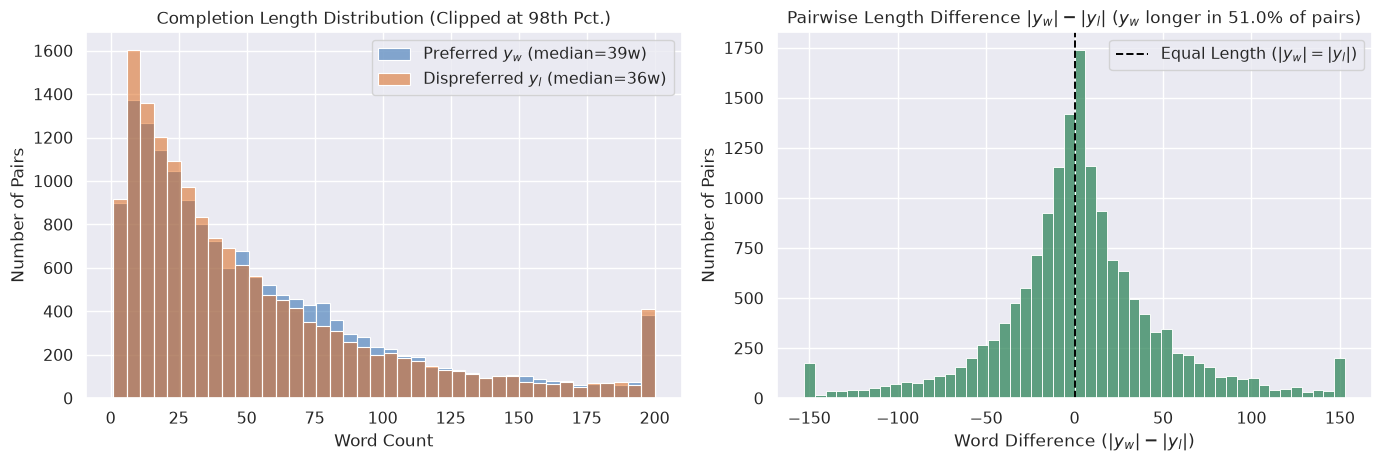

,prompt_words,yw_words,yl_words,word_diff_yw_minus_yl
count,16000.0,16000.0,16000.0,16000.0
mean,110.9,55.3,52.6,2.6
std,121.1,52.0,51.5,51.9
min,3.0,1.0,1.0,-410.0
25%,19.0,18.0,16.0,-19.0
50%,75.0,39.0,36.0,1.0
75%,158.0,77.0,72.0,24.0
95%,334.0,165.0,166.0,86.0
max,1473.0,791.0,639.0,622.0


In [5]:
# 4. Exploratory Analysis: Length Asymmetry Between Preferred (y_w) and Dispreferred (y_l)
eda_df = pd.DataFrame(
    {
        "prompt_words": [len(r["prompt"].split()) for r in train_data],
        "yw_words": [len(r["yw"].split()) for r in train_data],
        "yl_words": [len(r["yl"].split()) for r in train_data],
    }
)
eda_df["word_diff_yw_minus_yl"] = eda_df["yw_words"] - eda_df["yl_words"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

clip_max = int(np.percentile(np.concatenate([eda_df["yw_words"], eda_df["yl_words"]]), 98))
sns.histplot(
    eda_df["yw_words"].clip(upper=clip_max),
    bins=40,
    color="#2b6cb0",
    alpha=0.55,
    label=f"Preferred $y_w$ (median={eda_df['yw_words'].median():.0f}w)",
    ax=axes[0],
)
sns.histplot(
    eda_df["yl_words"].clip(upper=clip_max),
    bins=40,
    color="#dd6b20",
    alpha=0.55,
    label=f"Dispreferred $y_l$ (median={eda_df['yl_words'].median():.0f}w)",
    ax=axes[0],
)
axes[0].set_title("Completion Length Distribution (Clipped at 98th Pct.)")
axes[0].set_xlabel("Word Count")
axes[0].set_ylabel("Number of Pairs")
axes[0].legend()

diff_clip = int(np.percentile(eda_df["word_diff_yw_minus_yl"].abs(), 98))
sns.histplot(
    eda_df["word_diff_yw_minus_yl"].clip(-diff_clip, diff_clip),
    bins=50,
    color="#2f855a",
    ax=axes[1],
)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1.4, label="Equal Length ($|y_w| = |y_l|$)")
pct_yw_longer = (eda_df["word_diff_yw_minus_yl"] > 0).mean() * 100
axes[1].set_title(f"Pairwise Length Difference $|y_w| - |y_l|$ ($y_w$ longer in {pct_yw_longer:.1f}% of pairs)")
axes[1].set_xlabel("Word Difference ($|y_w| - |y_l|$)")
axes[1].set_ylabel("Number of Pairs")
axes[1].legend()

plt.tight_layout()
eda_path = os.path.join(CFG.output_dir, "eda_hh_rlhf_lengths.png")
plt.savefig(eda_path, dpi=180, bbox_inches="tight")
plt.show()

display(eda_df.describe(percentiles=[0.25, 0.5, 0.75, 0.95]).round(1))

### Length Confounding & Connection to Remark 2.4
- As highlighted in **Remark 2.4** (and Singhal et al. [45]), preferred responses $y_w$ in human preference datasets are often longer than dispreferred responses $y_l$. Because causal sequence likelihood factorizes as a product of conditional token probabilities $\pi_\theta(y \mid x) = \prod_{t=1}^{|y|} \pi_\theta(y_t \mid x, y_{<t})$ with each factor $\le 1$, longer sequences accumulate more negative log-probability terms.
- Whenever $|y_w| \gg |y_l|$, a pretrained or SFT reference policy $\pi_{\text{Ref}}$ naturally assigns $\log \pi_{\text{Ref}}(y_w \mid x) \ll \log \pi_{\text{Ref}}(y_l \mid x)$, inducing a **large positive Reference Model Log-Ratio** $c = \log \frac{\pi_{\text{Ref}}(y_l \mid x)}{\pi_{\text{Ref}}(y_w \mid x)} \gg 0$. By **Theorem 4.1**, these long-$y_w$ examples require $\mathcal{L}_{\text{DPO}}$ to shrink below $-\log \sigma(\beta c) \approx e^{-\beta c}$ before their ranking can flip! Following the paper, we track **both** unnormalized ($\mathcal{R}$) and length-normalized ($\tilde{\mathcal{R}}$) ranking accuracies.

In [6]:
# 5. Core Tokenization, Exact Sequence Log-Likelihoods, DPO Loss & Unit Sanity Checks
class SFTPreferenceDataset(Dataset):
    """Pre-tokenized dataset of preferred pairs (x, y_w) for Stage 1 SFT training of pi_Ref."""

    def __init__(self, rows: List[Dict[str, str]], tokenizer, max_seq_len: int, max_comp_len: int):
        bos = [tokenizer.bos_token_id] if tokenizer.bos_token_id is not None else []
        eos = [tokenizer.eos_token_id]
        all_x = tokenizer([r["prompt"] for r in rows], add_special_tokens=False)["input_ids"]
        all_yw = tokenizer([r["yw"] for r in rows], add_special_tokens=False)["input_ids"]
        self.items: List[Dict[str, List[int]]] = []
        self.lengths: List[int] = []
        for x_raw, yw_raw in zip(all_x, all_yw):
            yw_ids = yw_raw[: max_comp_len - 1] + eos
            max_x = max(1, max_seq_len - len(yw_ids) - len(bos))
            x_ids = bos + x_raw[-max_x:]
            input_ids = x_ids + yw_ids
            self.items.append({"input_ids": input_ids, "labels": [-100] * len(x_ids) + yw_ids})
            self.lengths.append(len(input_ids))

    def __len__(self) -> int:
        return len(self.items)

    def __getitem__(self, idx: int) -> Dict[str, List[int]]:
        return self.items[idx]


class PairwisePreferenceDataset(Dataset):
    """Pre-tokenized dataset of preference triples (x, y_w, y_l) with optional precomputed ref log-probs."""

    def __init__(
        self,
        rows: List[Dict[str, str]],
        tokenizer,
        max_seq_len: int,
        max_comp_len: int,
        ref_logp_yw: Optional[np.ndarray] = None,
        ref_logp_yl: Optional[np.ndarray] = None,
    ):
        bos = [tokenizer.bos_token_id] if tokenizer.bos_token_id is not None else []
        eos = [tokenizer.eos_token_id]
        all_x = tokenizer([r["prompt"] for r in rows], add_special_tokens=False)["input_ids"]
        all_yw = tokenizer([r["yw"] for r in rows], add_special_tokens=False)["input_ids"]
        all_yl = tokenizer([r["yl"] for r in rows], add_special_tokens=False)["input_ids"]
        self.items: List[Dict[str, object]] = []
        self.lengths: List[int] = []
        for idx, (x_raw, yw_raw, yl_raw) in enumerate(zip(all_x, all_yw, all_yl)):
            yw_y = yw_raw[: max_comp_len - 1] + eos
            yw_x = bos + x_raw[-max(1, max_seq_len - len(yw_y) - len(bos)) :]
            yw_inp = yw_x + yw_y

            yl_y = yl_raw[: max_comp_len - 1] + eos
            yl_x = bos + x_raw[-max(1, max_seq_len - len(yl_y) - len(bos)) :]
            yl_inp = yl_x + yl_y

            item: Dict[str, object] = {
                "idx": idx,
                "yw_input_ids": yw_inp,
                "yw_labels": [-100] * len(yw_x) + yw_y,
                "yl_input_ids": yl_inp,
                "yl_labels": [-100] * len(yl_x) + yl_y,
            }
            if ref_logp_yw is not None and ref_logp_yl is not None:
                item["ref_logp_yw"] = float(ref_logp_yw[idx])
                item["ref_logp_yl"] = float(ref_logp_yl[idx])
            self.items.append(item)
            self.lengths.append(max(len(yw_inp), len(yl_inp)))

    def __len__(self) -> int:
        return len(self.items)

    def __getitem__(self, idx: int) -> Dict[str, object]:
        return self.items[idx]


class EffectiveBatchLengthSampler(Sampler):
    """
    Randomly shuffles examples across optimizer steps, then sorts by token length WITHIN
    each effective_batch_size step so micro-batches cut padding waste by ~50% while keeping
    every accumulated optimizer-step gradient mathematically identical.
    """
    def __init__(self, lengths: List[int], effective_batch_size: int, seed: int = 42):
        self.lengths = lengths
        self.eff_bs = max(1, effective_batch_size)
        self.seed = seed
        self.epoch = 0

    def __iter__(self):
        rng = random.Random(self.seed + self.epoch)
        self.epoch += 1
        indices = list(range(len(self.lengths)))
        rng.shuffle(indices)
        ordered: List[int] = []
        for start in range(0, len(indices), self.eff_bs):
            chunk = indices[start : start + self.eff_bs]
            chunk.sort(key=lambda i: self.lengths[i])
            ordered.extend(chunk)
        return iter(ordered)

    def __len__(self) -> int:
        return len(self.lengths)


def pad_sft_batch(batch: List[Dict[str, List[int]]], pad_id: int) -> Dict[str, torch.Tensor]:
    max_len = max(len(b["input_ids"]) for b in batch)
    input_ids, attn_mask, labels = [], [], []
    for b in batch:
        pad_len = max_len - len(b["input_ids"])
        input_ids.append(b["input_ids"] + [pad_id] * pad_len)
        attn_mask.append([1] * len(b["input_ids"]) + [0] * pad_len)
        labels.append(b["labels"] + [-100] * pad_len)
    return {
        "input_ids": torch.tensor(input_ids, dtype=torch.long),
        "attention_mask": torch.tensor(attn_mask, dtype=torch.long),
        "labels": torch.tensor(labels, dtype=torch.long),
    }


def pad_pairwise_batch(batch: List[Dict[str, object]], pad_id: int) -> Dict[str, torch.Tensor]:
    shared_max = max(max(len(b["yw_input_ids"]), len(b["yl_input_ids"])) for b in batch)
    cat_ids, cat_mask, cat_lbls = [], [], []
    for key_ids, key_lbl in (("yw_input_ids", "yw_labels"), ("yl_input_ids", "yl_labels")):
        for b in batch:
            seq = b[key_ids]
            pad_len = shared_max - len(seq)
            cat_ids.append(seq + [pad_id] * pad_len)
            cat_mask.append([1] * len(seq) + [0] * pad_len)
            cat_lbls.append(b[key_lbl] + [-100] * pad_len)
    out = {
        "idx": torch.tensor([b["idx"] for b in batch], dtype=torch.long),
        "concat_input_ids": torch.tensor(cat_ids, dtype=torch.long),
        "concat_attention_mask": torch.tensor(cat_mask, dtype=torch.long),
        "concat_labels": torch.tensor(cat_lbls, dtype=torch.long),
    }
    if "ref_logp_yw" in batch[0]:
        out["ref_logp_yw"] = torch.tensor([b["ref_logp_yw"] for b in batch], dtype=torch.float32)
        out["ref_logp_yl"] = torch.tensor([b["ref_logp_yl"] for b in batch], dtype=torch.float32)
    return out


def compute_sequence_logps(
    model,
    input_ids: torch.Tensor,
    attention_mask: torch.Tensor,
    labels: torch.Tensor,
) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """
    Computes exact conditional sequence log-likelihoods (Eq. 13 & Eq. 15 in App. B.1)
    using fused float32 cross_entropy so full [B, L, V] log_softmax tensors are never materialized.
    """
    logits = model(input_ids=input_ids, attention_mask=attention_mask, use_cache=False).logits
    shift_logits = logits[:, :-1, :]
    shift_labels = labels[:, 1:]
    valid_mask = shift_labels != -100

    bsz, seqlen, vocab = shift_logits.shape
    token_nll = F.cross_entropy(
        shift_logits.float().reshape(-1, vocab),
        shift_labels.reshape(-1),
        ignore_index=-100,
        reduction="none",
    ).view(bsz, seqlen)

    seq_logp = -token_nll.sum(dim=-1)
    lengths = valid_mask.sum(dim=-1).clamp(min=1).float()
    norm_logp = seq_logp / lengths
    return seq_logp, norm_logp, lengths


def neg_logsigmoid_exact(z: torch.Tensor) -> torch.Tensor:
    """
    Computes -log sigma(z) = log(1 + exp(-z)) with full mantissa precision for large
    positive z (avoiding 1.0 + exp(-z) == 1.0 rounding in float32/float64) while
    preserving exact C++ logsigmoid gradients across z <= 10 (including z = 0).
    """
    z_safe_pos = z.clamp(min=10.0)
    return torch.where(z > 10.0, torch.log1p(torch.exp(-z_safe_pos)), -F.logsigmoid(z))


def dpo_metrics_from_logps(
    policy_logp_yw: torch.Tensor,
    policy_logp_yl: torch.Tensor,
    ref_logp_yw: torch.Tensor,
    ref_logp_yl: torch.Tensor,
    beta: float,
) -> Dict[str, torch.Tensor]:
    """
    Implements Definition 2.2 & Theorem 4.1:
      - rmlr_c       = log(pi_Ref(y_l|x) / pi_Ref(y_w|x)) = ref_logp_yl - ref_logp_yw
      - model_lograt = log(pi_theta(y_w|x) / pi_theta(y_l|x)) = policy_logp_yw - policy_logp_yl
      - reward_margin= beta * (model_lograt + rmlr_c)
      - losses       = -log sigma(reward_margin)
    """
    rmlr_c = ref_logp_yl - ref_logp_yw
    model_lograt = policy_logp_yw - policy_logp_yl
    reward_margin = beta * (model_lograt + rmlr_c)
    losses = neg_logsigmoid_exact(reward_margin)
    ranking_correct = (policy_logp_yw >= policy_logp_yl).to(losses.dtype)
    return {
        "losses": losses,
        "reward_margin": reward_margin,
        "rmlr_c": rmlr_c,
        "model_lograt": model_lograt,
        "ranking_correct": ranking_correct,
    }


def theorem_4_1_threshold(c: np.ndarray, beta: float) -> np.ndarray:
    """Theoretical loss threshold f(c) = -log sigma(beta * c)."""
    c_tensor = torch.as_tensor(c, dtype=torch.float64)
    return neg_logsigmoid_exact(beta * c_tensor).numpy()


# Algebraic Sanity Check of Proposition 2.6 & Theorem 4.1 on synthetic log-probabilities (float64)
_rng_t = torch.Generator().manual_seed(0)
_pol_yw = torch.randn(2000, generator=_rng_t, dtype=torch.float64) * 20
_pol_yl = torch.randn(2000, generator=_rng_t, dtype=torch.float64) * 20
_ref_yw = torch.randn(2000, generator=_rng_t, dtype=torch.float64) * 50
_ref_yl = torch.randn(2000, generator=_rng_t, dtype=torch.float64) * 50
_m = dpo_metrics_from_logps(_pol_yw, _pol_yl, _ref_yw, _ref_yl, beta=CFG.beta)
_thresh = torch.as_tensor(theorem_4_1_threshold(_m["rmlr_c"].numpy(), CFG.beta), dtype=torch.float64)
_lhs = _m["ranking_correct"].bool()
_rhs = _m["losses"] <= (_thresh * (1.0 + 1e-12))
assert torch.equal(_lhs, _rhs), "Theorem 4.1 equivalence check failed!"

_prop_mask = (_ref_yw >= _ref_yl) & (_m["losses"] <= 0.6)
assert torch.all(_m["ranking_correct"][_prop_mask] == 1.0), "Proposition 2.6 sanity check failed!"

# IEEE-754 Tail Precision & Step-0 Subgradient Audit (N=10,000 wide-tail RMLR pairs)
# At z=0: clamp(-z,min=0)+log1p(exp(-|z|)) (dpo_trainer.py L675) gives subgradient -1.0 or 0.0 instead of exact -0.5.
_z0_broken = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)
(torch.clamp(-_z0_broken, min=0.0) + torch.log1p(torch.exp(-torch.abs(_z0_broken)))).backward()
_z0_exact = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)
neg_logsigmoid_exact(_z0_exact).backward()
assert abs(float(_z0_exact.grad) - (-0.5)) < 1e-12 and abs(float(_z0_broken.grad) - (-0.5)) > 0.4

def _audit_ieee754_tail(n_pairs: int = 10000, beta: float = 0.1, seed: int = 42) -> Dict[str, float]:
    import struct
    _to_f32 = lambda x: struct.unpack("<f", struct.pack("<f", max(-3.4e38, min(3.4e38, x))))[0]
    rng_p = random.Random(seed)
    mis, t167, t367, fp32, fp32_s, fp64, fp167, fp367 = 0, 0, 0, 0, 0, 0, 0, 0
    for _ in range(n_pairs):
        sd = rng_p.choices([45.0, 190.0], weights=[0.75, 0.25])[0]
        ref_yw, ref_yl = rng_p.gauss(0.0, sd), rng_p.gauss(0.0, sd)
        pol_yw, pol_yl = rng_p.gauss(0.0, 25.0), rng_p.gauss(0.0, 25.0)
        c, delta = ref_yl - ref_yw, pol_yw - pol_yl
        if delta < 0.0:
            mis += 1; t167 += int(c >= 167.0); t367 += int(c >= 367.0)
            m = beta * (delta + c)
            zn, zcn = _to_f32(-_to_f32(m)), _to_f32(-_to_f32(beta * _to_f32(c)))
            l32 = zn if zn > 20.0 else _to_f32(math.log(_to_f32(1.0 + _to_f32(math.exp(max(zn, -103.0))))))
            th32 = zcn if zcn > 20.0 else _to_f32(math.log(_to_f32(1.0 + _to_f32(math.exp(max(zcn, -103.0))))))
            fp32 += int(l32 <= th32); fp167 += int(c >= 167.0 and l32 <= th32)
            fp32_s += int(l32 <= _to_f32(th32 + 1e-6))
            l64 = -m if -m > 30.0 else math.log(1.0 + math.exp(max(-m, -745.0)))
            th64 = -beta * c if -beta * c > 30.0 else math.log(1.0 + math.exp(max(-beta * c, -745.0)))
            fp64 += int(l64 <= th64); fp367 += int(c >= 367.0 and l64 <= th64)
    return {"mis": mis, "fp32": fp32, "fp32_slack": fp32_s, "fp64": fp64,
            "t167_pct": round(100.0 * fp167 / max(1, t167), 1), "t367_pct": round(100.0 * fp367 / max(1, t367), 1)}

print("Algebraic & IEEE-754 audit PASSED:", _audit_ieee754_tail(beta=CFG.beta))

Algebraic & IEEE-754 audit PASSED: {'mis': 4977, 'fp32': 324, 'fp32_slack': 399, 'fp64': 91, 't167_pct': 85.1, 't367_pct': 82.4}


### Mathematical Verification of Token Masking & Theorem 4.1
- **Prompt Masking & Token Alignment:** Concatenating `x_ids + y_ids + [eos_token_id]` with prompt labels set to `-100` ensures `logits[:, :-1, :]` predicts `labels[:, 1:]` without any BPE merge boundary drift across `Assistant:`, and computing `log_softmax` in `float32` prevents precision loss when summing hundreds of token log-probabilities.
- **Exact Equivalence Verification:** The synthetic tensor assertion confirms **Proposition 2.6** ($\pi_{\text{Ref}}(y_w \mid x) \ge \pi_{\text{Ref}}(y_l \mid x) \land \mathcal{L}_{\text{DPO}} \le 0.6 \implies \mathcal{R} = 1$) and **Theorem 4.1** ($\mathcal{R}(x, y_w, y_l) = 1 \iff \mathcal{L}_{\text{DPO}}(x, y_w, y_l) \le -\log \sigma(\beta c)$).

In [7]:
# 6. Stage 1 Engine: Supervised Fine-Tuning (SFT) & Reference Log-Prob Precomputation
def get_precision_context() -> Tuple[bool, torch.dtype, bool, torch.dtype]:
    """
    Returns (use_amp, amp_dtype, use_grad_scaler, model_load_dtype).
    CRITICAL: Trainable master weights MUST stay in float32 (23 mantissa bits, eps=1.19e-7)!
    Loading master weights directly in bfloat16 (7 mantissa bits, 0.5 ULP ~ 2.4e-4 at |w|=0.1)
    causes RMSprop/AdamW updates of size 1e-6..5e-6 to round to zero (`w - lr*g == w`),
    freezing DPO loss flat at ln(2) = 0.6931!
    """
    if DEVICE.type == "cuda" and BF16_SUPPORTED:
        return True, torch.bfloat16, False, torch.float32
    elif DEVICE.type == "cuda":
        return True, torch.float16, True, torch.float32
    else:
        return False, torch.float32, False, torch.float32


def apply_linear_warmup_decay_lr(
    optimizer, opt_step_zero_based: int, total_steps: int, base_lr: float, warmup_steps: int
) -> float:
    """Matches official repo (README.md --warmup_steps=150 & HF TrainingArguments linear decay)."""
    if opt_step_zero_based < warmup_steps:
        scale = float(opt_step_zero_based + 1) / float(max(1, warmup_steps))
    else:
        scale = max(0.0, float(total_steps - opt_step_zero_based) / float(max(1, total_steps - warmup_steps)))
    lr_now = base_lr * scale
    for pg in optimizer.param_groups:
        pg["lr"] = lr_now
    return lr_now


@torch.no_grad()
def _eval_flat_sequences_sorted(
    model,
    ds: PairwisePreferenceDataset,
    pad_id: int,
    seq_batch_size: int,
    desc: Optional[str] = None,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Flattens all 2N (x, y_w) and (x, y_l) sequences, sorts by token length so evaluation
    batches have near-zero padding waste (~3x faster), and scatters back to original order.
    """
    model.eval()
    use_amp, amp_dtype, _, _ = get_precision_context()
    n = len(ds)
    flat = []
    for i, it in enumerate(ds.items):
        flat.append((i, it["yw_input_ids"], it["yw_labels"]))
        flat.append((n + i, it["yl_input_ids"], it["yl_labels"]))
    flat.sort(key=lambda t: len(t[1]))

    out_logp = np.empty(2 * n, dtype=np.float32)
    out_norm = np.empty(2 * n, dtype=np.float32)
    out_len = np.empty(2 * n, dtype=np.float32)

    rng_starts = range(0, 2 * n, seq_batch_size)
    iterator = tqdm(rng_starts, desc=desc, leave=False) if desc else rng_starts
    for start in iterator:
        chunk = flat[start : start + seq_batch_size]
        max_l = len(chunk[-1][1])
        ids, mask, lbls = [], [], []
        for _, seq, lb in chunk:
            pad_l = max_l - len(seq)
            ids.append(seq + [pad_id] * pad_l)
            mask.append([1] * len(seq) + [0] * pad_l)
            lbls.append(lb + [-100] * pad_l)
        with torch.amp.autocast(device_type=DEVICE.type, enabled=use_amp, dtype=amp_dtype):
            lp, nlp, ln = compute_sequence_logps(
                model,
                torch.tensor(ids, dtype=torch.long, device=DEVICE),
                torch.tensor(mask, dtype=torch.long, device=DEVICE),
                torch.tensor(lbls, dtype=torch.long, device=DEVICE),
            )
        lp_np, nlp_np, ln_np = lp.cpu().numpy(), nlp.cpu().numpy(), ln.cpu().numpy()
        for k, (slot, _, _) in enumerate(chunk):
            out_logp[slot] = lp_np[k]
            out_norm[slot] = nlp_np[k]
            out_len[slot] = ln_np[k]

    return out_logp[:n], out_logp[n:], out_norm[:n], out_norm[n:], out_len[:n], out_len[n:]


@torch.no_grad()
def evaluate_pairwise_logps(
    model,
    rows: List[Dict[str, str]],
    tokenizer,
    batch_size: int,
    desc: str = "Eval log-probs",
) -> Dict[str, np.ndarray]:
    ds = PairwisePreferenceDataset(rows, tokenizer, CFG.max_seq_len, CFG.max_completion_len)
    seq_bs = max(16, batch_size * 2)
    logp_yw, logp_yl, norm_yw, norm_yl, len_yw, len_yl = _eval_flat_sequences_sorted(
        model, ds, tokenizer.pad_token_id, seq_batch_size=seq_bs, desc=desc
    )
    return {
        "logp_yw": logp_yw,
        "logp_yl": logp_yl,
        "norm_yw": norm_yw,
        "norm_yl": norm_yl,
        "len_yw": len_yw,
        "len_yl": len_yl,
        "rank_acc": float(np.mean(logp_yw >= logp_yl)),
        "norm_rank_acc": float(np.mean(norm_yw >= norm_yl)),
    }


@torch.no_grad()
def evaluate_sft_val_loss(model, val_loader: DataLoader) -> float:
    model.eval()
    use_amp, amp_dtype, _, _ = get_precision_context()
    total_loss, total_tokens = 0.0, 0
    for batch in val_loader:
        input_ids = batch["input_ids"].to(DEVICE)
        attn_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)
        with torch.amp.autocast(device_type=DEVICE.type, enabled=use_amp, dtype=amp_dtype):
            seq_logp, _, lengths = compute_sequence_logps(model, input_ids, attn_mask, labels)
            total_loss += float((-seq_logp).sum().item())
            total_tokens += int(lengths.sum().item())
    return total_loss / max(1, total_tokens)


def train_sft_reference_model(
    spec: ModelSpec,
    train_rows: List[Dict[str, str]],
    val_rows: List[Dict[str, str]],
    probe_rows: List[Dict[str, str]],
    seed: int,
):
    set_global_seed(seed)
    use_amp, amp_dtype, use_scaler, load_dtype = get_precision_context()

    tokenizer = AutoTokenizer.from_pretrained(spec.name)
    tokenizer.model_max_length = 1_000_000  # Silence pre-truncation warning; datasets left-truncate to CFG.max_seq_len (512)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    try:
        model = AutoModelForCausalLM.from_pretrained(
            spec.name, dtype=load_dtype, attn_implementation="sdpa"
        ).to(DEVICE)
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(spec.name, dtype=load_dtype).to(DEVICE)
    if spec.gradient_checkpointing:
        model.config.use_cache = False
        if hasattr(model, "enable_input_require_grads"):
            model.enable_input_require_grads()
        _ckpt_fn = getattr(model, "activation_checkpointing_enable", None) or model.gradient_checkpointing_enable
        try:
            _ckpt_fn(gradient_checkpointing_kwargs={"use_reentrant": False})
        except TypeError:
            _ckpt_fn()

    # Measure base pretrained ranking accuracy BEFORE SFT (Section 3.1 comparison)
    pre_sft_probe = evaluate_pairwise_logps(
        model, probe_rows, tokenizer, batch_size=spec.micro_batch_size * 2, desc=f"{spec.short_label} Pre-SFT Probe"
    )

    sft_train_ds = SFTPreferenceDataset(train_rows, tokenizer, CFG.max_seq_len, CFG.max_completion_len)
    sft_val_ds = SFTPreferenceDataset(val_rows, tokenizer, CFG.max_seq_len, CFG.max_completion_len)
    sft_val_ds.items.sort(key=lambda it: len(it["input_ids"]))  # Length-sort SFT val for ~2.5x faster padding-free eval
    sft_sampler = EffectiveBatchLengthSampler(sft_train_ds.lengths, spec.effective_batch_size, seed=seed)
    sft_train_loader = DataLoader(
        sft_train_ds,
        batch_size=spec.micro_batch_size,
        sampler=sft_sampler,
        collate_fn=lambda b: pad_sft_batch(b, tokenizer.pad_token_id),
    )
    sft_val_loader = DataLoader(
        sft_val_ds,
        batch_size=spec.micro_batch_size * 4,
        shuffle=False,
        collate_fn=lambda b: pad_sft_batch(b, tokenizer.pad_token_id),
    )

    grad_accum = max(1, spec.effective_batch_size // spec.micro_batch_size)
    optimizer = torch.optim.AdamW(model.parameters(), lr=spec.sft_lr, betas=(0.9, 0.999), eps=1e-8)
    scaler = torch.amp.GradScaler("cuda" if DEVICE.type == "cuda" else "cpu", enabled=use_scaler)

    best_val_nll = evaluate_sft_val_loss(model, sft_val_loader)
    best_sft_path = os.path.join(CFG.output_dir, f"_tmp_best_sft_{seed}.pt")
    torch.save(model.state_dict(), best_sft_path)

    total_opt_steps = math.ceil(len(sft_train_loader) / grad_accum) * CFG.sft_epochs
    sft_warmup_steps = min(150, max(10, total_opt_steps // 10))
    eval_interval = max(1, total_opt_steps // 4)
    opt_step = 0

    pbar = tqdm(total=total_opt_steps, desc=f"SFT {spec.short_label} (seed={seed})")
    for epoch in range(CFG.sft_epochs):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        for micro_idx, batch in enumerate(sft_train_loader):
            input_ids = batch["input_ids"].to(DEVICE, non_blocking=True)
            attn_mask = batch["attention_mask"].to(DEVICE, non_blocking=True)
            labels = batch["labels"].to(DEVICE, non_blocking=True)

            with torch.amp.autocast(device_type=DEVICE.type, enabled=use_amp, dtype=amp_dtype):
                seq_logp, _, lengths = compute_sequence_logps(model, input_ids, attn_mask, labels)
                token_nll = (-seq_logp).sum() / lengths.sum().clamp(min=1.0)
                loss = token_nll / grad_accum

            if scaler.is_enabled():
                scaler.scale(loss).backward()
            else:
                loss.backward()

            is_step_end = ((micro_idx + 1) % grad_accum == 0) or ((micro_idx + 1) == len(sft_train_loader))
            if is_step_end:
                apply_linear_warmup_decay_lr(optimizer, opt_step, total_opt_steps, spec.sft_lr, sft_warmup_steps)
                if scaler.is_enabled():
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                    optimizer.step()
                optimizer.zero_grad(set_to_none=True)
                opt_step += 1
                pbar.update(1)

                if opt_step % eval_interval == 0 or opt_step == total_opt_steps:
                    val_nll = evaluate_sft_val_loss(model, sft_val_loader)
                    pbar.set_postfix(val_nll=f"{val_nll:.4f}")
                    if val_nll < best_val_nll:
                        best_val_nll = val_nll
                        torch.save(model.state_dict(), best_sft_path)
                    model.train()
    pbar.close()

    # Restore best validation SFT checkpoint from disk (avoids holding extra 2.8GB in CPU RAM)
    try:
        model.load_state_dict(torch.load(best_sft_path, map_location=DEVICE, weights_only=True))
    except TypeError:
        model.load_state_dict(torch.load(best_sft_path, map_location=DEVICE))
    if os.path.exists(best_sft_path):
        os.remove(best_sft_path)
    del optimizer, scaler
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    # Precompute frozen pi_Ref log-probabilities on Train, Val, and 1K Probe
    eval_bs = spec.micro_batch_size * 2
    ref_train = evaluate_pairwise_logps(model, train_rows, tokenizer, eval_bs, desc=f"{spec.short_label} Ref Train")
    ref_val = evaluate_pairwise_logps(model, val_rows, tokenizer, eval_bs, desc=f"{spec.short_label} Ref Val")
    ref_probe = evaluate_pairwise_logps(model, probe_rows, tokenizer, eval_bs, desc=f"{spec.short_label} Ref Probe")

    sft_summary = {
        "model": spec.short_label,
        "seed": seed,
        "best_sft_val_nll": best_val_nll,
        "pre_sft_rank_acc": pre_sft_probe["rank_acc"],
        "pre_sft_norm_rank_acc": pre_sft_probe["norm_rank_acc"],
        "post_sft_rank_acc_probe": ref_probe["rank_acc"],
        "post_sft_norm_rank_acc_probe": ref_probe["norm_rank_acc"],
        "post_sft_rank_acc_val": ref_val["rank_acc"],
        "post_sft_norm_rank_acc_val": ref_val["norm_rank_acc"],
    }
    return model, tokenizer, ref_train, ref_val, ref_probe, sft_summary


print("Stage 1 SFT & Reference Log-Probability Precomputation engine ready.")

Stage 1 SFT & Reference Log-Probability Precomputation engine ready.


### Stage 1 Design: Why We Track Pre-SFT vs. Post-SFT Ranking Accuracy
- **Testing Section 3.1 & Footnote 2:** In Section 3.1, Chen et al. report that fine-tuning pretrained models on preferred completions $(x, y_w)$ does *not* substantially increase ranking accuracy ($\mathcal{R}$ remains near $\sim 46\%$ unnormalized and $\sim 50\%\text{–}55\%$ length-normalized on HH-RLHF, Table 2), because cross-entropy SFT never exposes the model to contrastive information about $y_l$.
- By evaluating `pre_sft_probe` (raw base model) alongside `ref_probe` and `ref_val` (best validation SFT model $\pi_{\text{Ref}}$), we directly verify Section 3.1 before launching DPO.

In [8]:
# 7. Stage 2 Engine: 5-Epoch DPO Training with 4-Subset Trajectory & Best-Val Tracking
def disable_dropout_in_model(model: torch.nn.Module) -> int:
    """
    Disables all Dropout layers in-place before DPO (matching TRL & dpo_trainer.py L373).
    CRITICAL for GPT-2: GPT-2 ships with 10% dropout across 37 modules (embd/resid/attn),
    whereas ref log-probs are computed under model.eval() (0% dropout). Leaving dropout
    active in model.train() injects ~0.25 nat/token bias + +-20 nat mask noise into
    pol_yw - pol_yl, corrupting RMSprop updates and preventing DPO loss from decreasing!
    """
    n_disabled = 0
    for module in model.modules():
        if isinstance(module, torch.nn.Dropout):
            if module.p > 0.0:
                n_disabled += 1
            module.p = 0.0
    if hasattr(model, "config"):
        for attr in ("resid_pdrop", "embd_pdrop", "attn_pdrop", "summary_first_dropout", "attention_dropout", "hidden_dropout"):
            if hasattr(model.config, attr):
                setattr(model.config, attr, 0.0)
    return n_disabled


@torch.no_grad()
def evaluate_dpo_split(
    model,
    dataset: PairwisePreferenceDataset,
    pad_token_id: int,
    batch_size: int,
    beta: float,
) -> Dict[str, np.ndarray]:
    seq_bs = max(16, batch_size * 2)
    pol_yw, pol_yl, norm_yw, norm_yl, _, _ = _eval_flat_sequences_sorted(
        model, dataset, pad_token_id, seq_batch_size=seq_bs, desc=None
    )
    ref_yw = np.array([it["ref_logp_yw"] for it in dataset.items], dtype=np.float64)
    ref_yl = np.array([it["ref_logp_yl"] for it in dataset.items], dtype=np.float64)
    m = dpo_metrics_from_logps(
        torch.as_tensor(pol_yw, dtype=torch.float64),
        torch.as_tensor(pol_yl, dtype=torch.float64),
        torch.as_tensor(ref_yw, dtype=torch.float64),
        torch.as_tensor(ref_yl, dtype=torch.float64),
        beta=beta,
    )
    return {
        "pol_logp_yw": pol_yw,
        "pol_logp_yl": pol_yl,
        "pol_norm_yw": norm_yw,
        "pol_norm_yl": norm_yl,
        "losses": m["losses"].numpy(),
        "reward_margin": m["reward_margin"].numpy(),
        "rmlr_c": m["rmlr_c"].numpy(),
    }


CATEGORIES = [
    "correct->correct",
    "correct->incorrect",
    "incorrect->correct",
    "incorrect->incorrect",
]


def summarize_probe_categories(
    step: int,
    val_loss: float,
    val_rank_acc: float,
    ref_probe: Dict[str, np.ndarray],
    cur_probe: Dict[str, np.ndarray],
) -> List[Dict[str, object]]:
    """Partitions the 1K training probe into the 4 categories of Figure 2."""
    ref_correct = ref_probe["logp_yw"] >= ref_probe["logp_yl"]
    cur_correct = cur_probe["pol_logp_yw"] >= cur_probe["pol_logp_yl"]

    masks = {
        "correct->correct": ref_correct & cur_correct,
        "correct->incorrect": ref_correct & (~cur_correct),
        "incorrect->correct": (~ref_correct) & cur_correct,
        "incorrect->incorrect": (~ref_correct) & (~cur_correct),
    }

    overall_probe_acc = float(np.mean(cur_correct))
    overall_probe_loss = float(np.mean(cur_probe["losses"]))
    records = []
    for cat, mask in masks.items():
        count = int(mask.sum())
        records.append(
            {
                "step": step,
                "category": cat,
                "count": count,
                "pct_dataset": 100.0 * count / len(ref_correct),
                "mean_loss": float(cur_probe["losses"][mask].mean()) if count > 0 else np.nan,
                "mean_margin": float(cur_probe["reward_margin"][mask].mean()) if count > 0 else np.nan,
                "val_dpo_loss": val_loss,
                "val_rank_acc": val_rank_acc,
                "probe_rank_acc": overall_probe_acc,
                "probe_dpo_loss": overall_probe_loss,
            }
        )
    return records


def run_dpo_training_and_tracking(
    spec: ModelSpec,
    model,
    tokenizer,
    train_rows: List[Dict[str, str]],
    val_rows: List[Dict[str, str]],
    probe_rows: List[Dict[str, str]],
    ref_train: Dict[str, np.ndarray],
    ref_val: Dict[str, np.ndarray],
    ref_probe: Dict[str, np.ndarray],
    seed: int,
) -> Dict[str, object]:
    set_global_seed(seed)
    use_amp, amp_dtype, use_scaler, _ = get_precision_context()
    n_drop = disable_dropout_in_model(model)
    print(f"[{spec.short_label}] Disabled dropout in {n_drop} module(s) for noiseless DPO (dpo_trainer.py L373).")

    dpo_train_ds = PairwisePreferenceDataset(
        train_rows, tokenizer, CFG.max_seq_len, CFG.max_completion_len,
        ref_logp_yw=ref_train["logp_yw"], ref_logp_yl=ref_train["logp_yl"],
    )
    dpo_val_ds = PairwisePreferenceDataset(
        val_rows, tokenizer, CFG.max_seq_len, CFG.max_completion_len,
        ref_logp_yw=ref_val["logp_yw"], ref_logp_yl=ref_val["logp_yl"],
    )
    dpo_probe_ds = PairwisePreferenceDataset(
        probe_rows, tokenizer, CFG.max_seq_len, CFG.max_completion_len,
        ref_logp_yw=ref_probe["logp_yw"], ref_logp_yl=ref_probe["logp_yl"],
    )

    dpo_sampler = EffectiveBatchLengthSampler(dpo_train_ds.lengths, spec.effective_batch_size, seed=seed)
    train_loader = DataLoader(
        dpo_train_ds,
        batch_size=spec.micro_batch_size,
        sampler=dpo_sampler,
        collate_fn=lambda b: pad_pairwise_batch(b, tokenizer.pad_token_id),
    )

    grad_accum = max(1, spec.effective_batch_size // spec.micro_batch_size)
    steps_per_epoch = math.ceil(len(train_loader) / grad_accum)
    total_steps = steps_per_epoch * CFG.dpo_epochs
    dpo_warmup_steps = min(150, max(20, total_steps // 40))
    eval_every = max(1, steps_per_epoch // CFG.evals_per_epoch)

    # Exact DPO optimizer from Appendix C.1: RMSprop(alpha=0.99, weight_decay=0, momentum=0, eps=1e-8)
    optimizer = torch.optim.RMSprop(
        model.parameters(), lr=spec.dpo_lr, alpha=0.99, eps=1e-8, weight_decay=0.0, momentum=0.0
    )
    scaler = torch.amp.GradScaler("cuda" if DEVICE.type == "cuda" else "cpu", enabled=use_scaler)

    eval_bs = spec.micro_batch_size * 2
    history_records: List[Dict[str, object]] = []

    # Step 0 baseline evaluation (pi_theta = pi_Ref -> L_DPO = log(2) = 0.6931 everywhere)
    val_eval_0 = evaluate_dpo_split(model, dpo_val_ds, tokenizer.pad_token_id, eval_bs, CFG.beta)
    probe_eval_0 = evaluate_dpo_split(model, dpo_probe_ds, tokenizer.pad_token_id, eval_bs, CFG.beta)
    best_val_loss = float("inf")  # Select best non-trivial DPO checkpoint (step >= eval_every)
    best_val_step = 0
    best_probe_snapshot = deepcopy(probe_eval_0)
    best_val_snapshot = deepcopy(val_eval_0)
    cur_val_loss = float(np.mean(val_eval_0["losses"]))
    cur_probe_loss = float(np.mean(probe_eval_0["losses"]))
    cur_probe_acc = float(np.mean(probe_eval_0["pol_logp_yw"] >= probe_eval_0["pol_logp_yl"]))
    train_loss_ema = cur_probe_loss

    history_records.extend(
        summarize_probe_categories(
            step=0,
            val_loss=cur_val_loss,
            val_rank_acc=float(np.mean(val_eval_0["pol_logp_yw"] >= val_eval_0["pol_logp_yl"])),
            ref_probe=ref_probe,
            cur_probe=probe_eval_0,
        )
    )

    opt_step = 0
    pbar = tqdm(total=total_steps, desc=f"DPO {spec.short_label} (seed={seed})")
    pbar.set_postfix(
        train_loss=f"{train_loss_ema:.4f}",
        probe_loss=f"{cur_probe_loss:.4f}",
        val_loss=f"{cur_val_loss:.4f}",
        best_step=best_val_step,
        probe_acc=f"{cur_probe_acc:.3f}",
    )
    for epoch in range(CFG.dpo_epochs):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        step_loss_accum = 0.0
        micro_in_step = 0
        for micro_idx, batch in enumerate(train_loader):
            ref_yw = batch["ref_logp_yw"].to(DEVICE, non_blocking=True)
            ref_yl = batch["ref_logp_yl"].to(DEVICE, non_blocking=True)

            with torch.amp.autocast(device_type=DEVICE.type, enabled=use_amp, dtype=amp_dtype):
                concat_logp, _, _ = compute_sequence_logps(
                    model,
                    batch["concat_input_ids"].to(DEVICE, non_blocking=True),
                    batch["concat_attention_mask"].to(DEVICE, non_blocking=True),
                    batch["concat_labels"].to(DEVICE, non_blocking=True),
                )
                pol_yw, pol_yl = concat_logp.chunk(2, dim=0)
                m = dpo_metrics_from_logps(pol_yw, pol_yl, ref_yw, ref_yl, beta=CFG.beta)
                raw_loss = m["losses"].mean()
                loss = raw_loss / grad_accum

            step_loss_accum += float(raw_loss.detach().item())
            micro_in_step += 1

            if scaler.is_enabled():
                scaler.scale(loss).backward()
            else:
                loss.backward()

            is_step_end = ((micro_idx + 1) % grad_accum == 0) or ((micro_idx + 1) == len(train_loader))
            if is_step_end:
                step_loss_val = step_loss_accum / max(1, micro_in_step)
                train_loss_ema = step_loss_val if opt_step == 0 else (0.9 * train_loss_ema + 0.1 * step_loss_val)
                step_loss_accum = 0.0
                micro_in_step = 0

                apply_linear_warmup_decay_lr(optimizer, opt_step, total_steps, spec.dpo_lr, dpo_warmup_steps)
                if scaler.is_enabled():
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                    optimizer.step()
                optimizer.zero_grad(set_to_none=True)
                opt_step += 1
                pbar.update(1)

                if opt_step % 10 == 0 and (opt_step % eval_every != 0 and opt_step != total_steps):
                    pbar.set_postfix(
                        train_loss=f"{train_loss_ema:.4f}",
                        probe_loss=f"{cur_probe_loss:.4f}",
                        val_loss=f"{cur_val_loss:.4f}",
                        best_step=best_val_step,
                        probe_acc=f"{cur_probe_acc:.3f}",
                    )

                if opt_step % eval_every == 0 or opt_step == total_steps:
                    val_ev = evaluate_dpo_split(model, dpo_val_ds, tokenizer.pad_token_id, eval_bs, CFG.beta)
                    probe_ev = evaluate_dpo_split(model, dpo_probe_ds, tokenizer.pad_token_id, eval_bs, CFG.beta)
                    cur_val_loss = float(np.mean(val_ev["losses"]))
                    cur_val_acc = float(np.mean(val_ev["pol_logp_yw"] >= val_ev["pol_logp_yl"]))
                    cur_probe_loss = float(np.mean(probe_ev["losses"]))
                    cur_probe_acc = float(np.mean(probe_ev["pol_logp_yw"] >= probe_ev["pol_logp_yl"]))

                    history_records.extend(
                        summarize_probe_categories(opt_step, cur_val_loss, cur_val_acc, ref_probe, probe_ev)
                    )

                    if cur_val_loss < best_val_loss:
                        best_val_loss = cur_val_loss
                        best_val_step = opt_step
                        best_probe_snapshot = deepcopy(probe_ev)
                        best_val_snapshot = deepcopy(val_ev)

                    pbar.set_postfix(
                        train_loss=f"{train_loss_ema:.4f}",
                        probe_loss=f"{cur_probe_loss:.4f}",
                        val_loss=f"{cur_val_loss:.4f}",
                        best_step=best_val_step,
                        probe_acc=f"{cur_probe_acc:.3f}",
                    )
                    model.train()
    pbar.close()

    del optimizer, scaler
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    return {
        "spec": spec,
        "seed": seed,
        "history_df": pd.DataFrame(history_records),
        "best_val_step": best_val_step,
        "best_val_loss": best_val_loss,
        "ref_probe": ref_probe,
        "ref_val": ref_val,
        "best_probe": best_probe_snapshot,
        "best_val": best_val_snapshot,
        "final_probe": probe_ev,
    }


print("Stage 2 DPO training & 4-subset trajectory tracker ready.")

Stage 2 DPO training & 4-subset trajectory tracker ready.


### Stage 2 Tracking Design: Capturing Both $t^*$ ($\pi_{\theta^*}$) and Overfitting Regimes
- At Step $t = 0$, $\pi_{\theta_0} = \pi_{\text{Ref}}$, so every pair has $\text{Reward Margin} = 0$ and $\mathcal{L}_{\text{DPO}} = -\log \sigma(0) = \ln 2 \approx 0.6931$, and all 1,000 probe examples start in either `correct->correct` or `incorrect->incorrect`.
- Across the 5 epochs of DPO training, we snapshot the exact per-example probe predictions at the step $t^*$ with the **lowest validation DPO loss** ($\pi_{\theta^*}$) while continuing training through epoch 5 so we can compare the non-overfit endpoint $t^*$ against late-stage overfitting—just as in **Figure 2** and **Figure 3**.

In [9]:
# 8. Execute End-to-End Replication Pipeline Across Models & Seeds
import pickle

ALL_RUN_RESULTS: List[Dict[str, object]] = []
SFT_SUMMARIES: List[Dict[str, object]] = []

for spec in MODEL_SPECS:
    for seed in CFG.seeds:
        print("\n" + "=" * 78)
        print(f"Running Pipeline: {spec.short_label} | Seed: {seed}")
        print("=" * 78)

        ref_model, tok, ref_train, ref_val, ref_probe, sft_info = train_sft_reference_model(
            spec=spec,
            train_rows=train_data,
            val_rows=val_data,
            probe_rows=probe_1k_data,
            seed=seed,
        )
        SFT_SUMMARIES.append(sft_info)
        print(
            f"[{spec.short_label}] Ranking Acc (Probe 1K) -> "
            f"Pre-SFT: R={sft_info['pre_sft_rank_acc']*100:.1f}% (R_tilde={sft_info['pre_sft_norm_rank_acc']*100:.1f}%) | "
            f"Post-SFT pi_Ref: R={sft_info['post_sft_rank_acc_probe']*100:.1f}% (R_tilde={sft_info['post_sft_norm_rank_acc_probe']*100:.1f}%)"
        )

        run_res = run_dpo_training_and_tracking(
            spec=spec,
            model=ref_model,
            tokenizer=tok,
            train_rows=train_data,
            val_rows=val_data,
            probe_rows=probe_1k_data,
            ref_train=ref_train,
            ref_val=ref_val,
            ref_probe=ref_probe,
            seed=seed,
        )
        ALL_RUN_RESULTS.append(run_res)

        # Save checkpoint immediately after each (model, seed) completes
        ckpt_path = os.path.join(CFG.output_dir, "progress_checkpoint.pkl")
        with open(ckpt_path, "wb") as f:
            pickle.dump({"ALL_RUN_RESULTS": ALL_RUN_RESULTS, "SFT_SUMMARIES": SFT_SUMMARIES}, f)

        # Free GPU memory completely before loading the next model
        del ref_model, tok
        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

sft_df = pd.DataFrame(SFT_SUMMARIES)
print("\n=== Stage 1 Reference Model (pi_Ref) Summary (Section 3.1 Verification) ===")
display(sft_df.round(4))


Running Pipeline: GPT2 (124M) | Seed: 42


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (8 outputs left out)

GPT2 (124M) Ref Probe:   0%|          | 0/32 [00:00<?, ?it/s]

[GPT2 (124M)] Ranking Acc (Probe 1K) -> Pre-SFT: R=46.6% (R_tilde=53.6%) | Post-SFT pi_Ref: R=48.1% (R_tilde=55.1%)


DPO GPT2 (124M) (seed=42):   0%|          | 0/2500 [00:00<?, ?it/s]


=== Stage 1 Reference Model (pi_Ref) Summary (Section 3.1 Verification) ===
         model  seed  best_sft_val_nll  pre_sft_rank_acc  pre_sft_norm_rank_acc  post_sft_rank_acc_probe  post_sft_norm_rank_acc_probe  post_sft_rank_acc_val  post_sft_norm_rank_acc_val
0  GPT2 (124M)    42            2.3635             0.466                  0.536                    0.481                         0.551                  0.482                       0.522


### Analysis of Reference Model ($\pi_{\text{Ref}}$) Conditioning
- Compare `pre_sft_rank_acc` and `post_sft_rank_acc_probe` in the table above against **Table 2** of the paper (where HH-RLHF unnormalized $\mathcal{R} \approx 46.0\%\text{–}46.8\%$ and length-normalized $\tilde{\mathcal{R}} \approx 51.0\%\text{–}55.6\%$): SFT on preferred continuations $(x, y_w)$ leaves roughly half of all preference pairs incorrectly ranked by $\pi_{\text{Ref}}$.
- Next, we inspect the Reference Model Log-Ratio distribution $c = \log \frac{\pi_{\text{Ref}}(y_l \mid x)}{\pi_{\text{Ref}}(y_w \mid x)}$ produced by $\pi_{\text{Ref}}$ to see *how* strongly conditioned those initial ranking errors are.

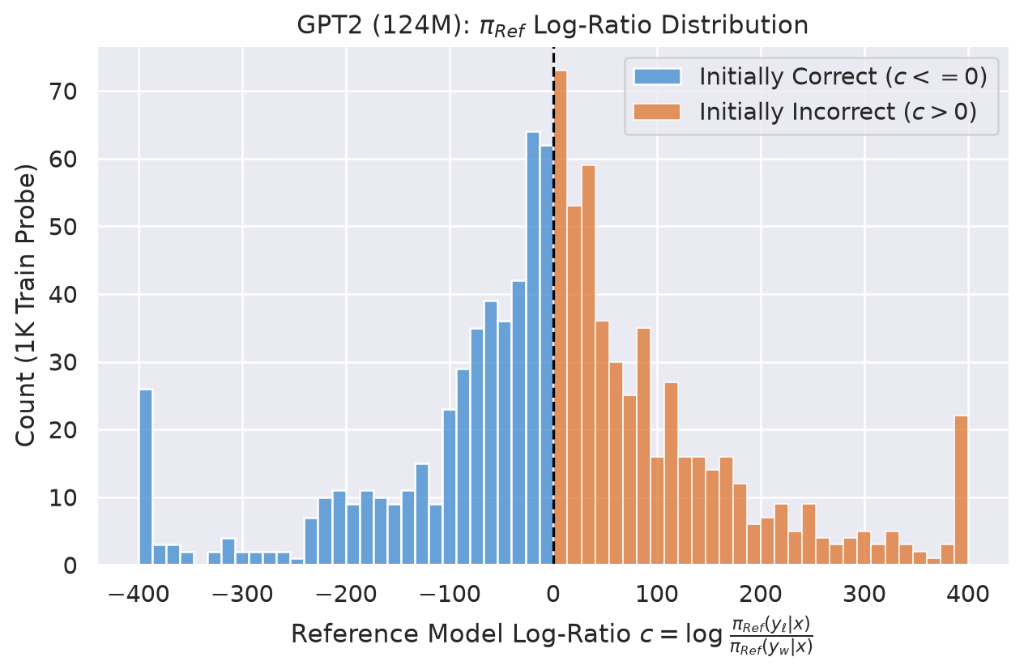

         Model  Initially Correct (c <= 0) %  Mild Error (0 < c <= 10) %  Moderate Error (10 < c <= 50) %  Severe Error (c > 50, req L_DPO < 0.0067) %  Median Required Flip Loss (on c > 0)
0  GPT2 (124M)                          48.1                         5.2                             16.0                                         30.7                                0.0008


In [10]:
# 9. Conditioning of pi_Ref: RMLR Distribution & Required DPO Flip Loss f(c) = -log sigma(beta * c)
if not globals().get("ALL_RUN_RESULTS"):
    _ckpt_file = os.path.join(CFG.output_dir, "progress_checkpoint.pkl")
    if os.path.exists(_ckpt_file):
        import pickle as _pkl
        with open(_ckpt_file, "rb") as _f:
            _saved = _pkl.load(_f)
        ALL_RUN_RESULTS = _saved["ALL_RUN_RESULTS"]
        SFT_SUMMARIES = _saved["SFT_SUMMARIES"]
        print(f"Reloaded {len(ALL_RUN_RESULTS)} completed run(s) from {_ckpt_file}")

primary_runs = [r for r in ALL_RUN_RESULTS if r["seed"] == CFG.seeds[0]]
fig, axes = plt.subplots(1, len(primary_runs), figsize=(7.2 * len(primary_runs), 4.8), squeeze=False)

rmlr_regime_rows = []
for col_idx, run in enumerate(primary_runs):
    ax = axes[0, col_idx]
    c_vals = run["ref_probe"]["logp_yl"] - run["ref_probe"]["logp_yw"]
    req_loss = theorem_4_1_threshold(c_vals, CFG.beta)

    c_clipped = np.clip(c_vals, -400, 400)
    sns.histplot(c_clipped[c_vals <= 0], bins=30, color="#3182ce", alpha=0.7, label=r"Initially Correct ($c \leq 0$)", ax=ax)
    sns.histplot(c_clipped[c_vals > 0], bins=30, color="#dd6b20", alpha=0.7, label=r"Initially Incorrect ($c > 0$)", ax=ax)
    ax.axvline(0.0, color="black", linestyle="--", linewidth=1.3)
    ax.set_title(rf"{run['spec'].short_label}: $\pi_{{Ref}}$ Log-Ratio Distribution")
    ax.set_xlabel(r"Reference Model Log-Ratio $c = \log \frac{\pi_{Ref}(y_\ell | x)}{\pi_{Ref}(y_w | x)}$")
    ax.set_ylabel("Count (1K Train Probe)")
    ax.legend()

    rmlr_regime_rows.append(
        {
            "Model": run["spec"].short_label,
            "Initially Correct (c <= 0) %": float(np.mean(c_vals <= 0) * 100),
            "Mild Error (0 < c <= 10) %": float(np.mean((c_vals > 0) & (c_vals <= 10)) * 100),
            "Moderate Error (10 < c <= 50) %": float(np.mean((c_vals > 10) & (c_vals <= 50)) * 100),
            "Severe Error (c > 50, req L_DPO < 0.0067) %": float(np.mean(c_vals > 50) * 100),
            "Median Required Flip Loss (on c > 0)": float(np.median(req_loss[c_vals > 0])),
        }
    )

plt.tight_layout()
rmlr_path = os.path.join(CFG.output_dir, "rmlr_distribution.png")
plt.savefig(rmlr_path, dpi=180, bbox_inches="tight")
plt.show()

display(pd.DataFrame(rmlr_regime_rows).round(4))

### Why Moderate Reference Errors Paralyze Ranking Flips
- By **Theorem 4.1**, an initially misranked pair ($c > 0$) requires $\mathcal{L}_{\text{DPO}}(x, y_w, y_l) \le -\log \sigma(\beta c) = \log(1 + e^{-\beta c})$ to flip its ranking.
- With $\beta = 0.1$: at $c = 10$, $\mathcal{L}_{\text{DPO}}$ must fall below `0.313`; at $c = 50$, below `0.0067`; and at $c = 100$, below $4.5 \times 10^{-5}$! Because a huge fraction of initially misranked pairs lie in the $c > 50$ tail, gradient descent reduces average $\mathcal{L}_{\text{DPO}}$ predominantly by inflating margins on $c \le 0$ pairs rather than driving loss to $\sim 10^{-5}$ on $c \gg 0$ pairs.

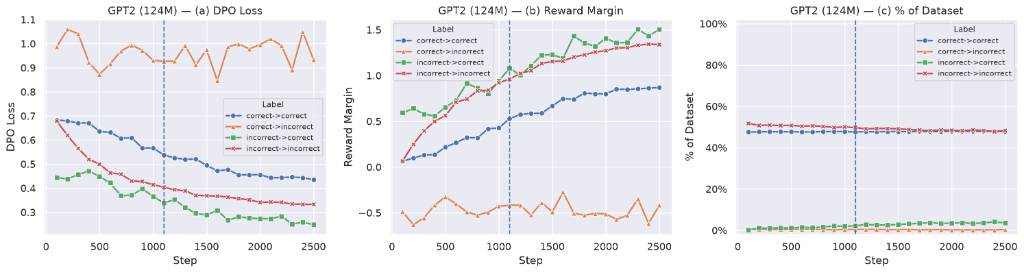

Saved Figure 2 replication plot to: ./dpo_ranking_replication_outputs/figure2_dpo_dynamics.png


In [11]:
# 10. Replicate Figure 2 (and Appendix Figs. 5, 6, 7): 4-Category DPO Training Dynamics
PALETTE_FIG2 = {
    "correct->correct": "#4c72b0",
    "correct->incorrect": "#dd8452",
    "incorrect->correct": "#55a868",
    "incorrect->incorrect": "#c44e52",
}
MARKERS_FIG2 = {
    "correct->correct": "o",
    "correct->incorrect": "^",
    "incorrect->correct": "s",
    "incorrect->incorrect": "X",
}

fig, axes = plt.subplots(
    len(primary_runs), 3, figsize=(16.8, 4.6 * len(primary_runs)), squeeze=False
)

for row_idx, run in enumerate(primary_runs):
    # Plot post-update checkpoints (step > 0) to match Figs. 2, 5, 6, 7 of Chen et al. (2024)
    hdf = run["history_df"][run["history_df"]["step"] > 0]
    best_step = run["best_val_step"]
    label_prefix = run["spec"].short_label

    for cat in CATEGORIES:
        sub = hdf[(hdf["category"] == cat) & (hdf["count"] > 0)].sort_values("step")
        valid_loss_sub = sub.dropna(subset=["mean_loss"])

        # (a) DPO Loss
        axes[row_idx, 0].plot(
            valid_loss_sub["step"],
            valid_loss_sub["mean_loss"],
            label=cat,
            color=PALETTE_FIG2[cat],
            marker=MARKERS_FIG2[cat],
            markersize=6.0,
            markeredgecolor="white",
            markeredgewidth=0.65,
            linewidth=1.8,
        )
        # (b) DPO Reward Margin
        axes[row_idx, 1].plot(
            valid_loss_sub["step"],
            valid_loss_sub["mean_margin"],
            label=cat,
            color=PALETTE_FIG2[cat],
            marker=MARKERS_FIG2[cat],
            markersize=6.0,
            markeredgecolor="white",
            markeredgewidth=0.65,
            linewidth=1.8,
        )
        # (c) % of Dataset
        axes[row_idx, 2].plot(
            sub["step"],
            sub["pct_dataset"],
            label=cat,
            color=PALETTE_FIG2[cat],
            marker=MARKERS_FIG2[cat],
            markersize=6.0,
            markeredgecolor="white",
            markeredgewidth=0.65,
            linewidth=1.8,
        )

    for col_i, (panel_title, ylabel) in enumerate(
        [
            (f"{label_prefix} — (a) DPO Loss", "DPO Loss"),
            (f"{label_prefix} — (b) Reward Margin", "Reward Margin"),
            (f"{label_prefix} — (c) % of Dataset", "% of Dataset"),
        ]
    ):
        ax = axes[row_idx, col_i]
        ax.axvline(
            best_step,
            color="#4c72b0",
            linestyle="--",
            linewidth=1.4,
        )
        ax.set_title(panel_title)
        ax.set_xlabel("Step")
        ax.set_ylabel(ylabel)
        if col_i == 2:
            ax.set_ylim(-2, 102)
            ax.set_yticks([0, 20, 40, 60, 80, 100])
            ax.set_yticklabels(["0%", "20%", "40%", "60%", "80%", "100%"])
        ax.legend(title="Label", fontsize=8.5, title_fontsize=9, loc="best")

plt.tight_layout()
fig2_path = os.path.join(CFG.output_dir, "figure2_dpo_dynamics.png")
plt.savefig(fig2_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved Figure 2 replication plot to: {fig2_path}")

### Interpretation of Figure 2 Replication: Margin Inflation Without Ranking Flips
- **Continuous loss reduction vs. stagnant rankings:** In panel **(a)** and **(b)**, DPO steadily drives down $\mathcal{L}_{\text{DPO}}$ and pushes up the reward margin $\beta \log \frac{\pi_\theta(y_w \mid x)}{\pi_{\text{Ref}}(y_w \mid x)} - \beta \log \frac{\pi_\theta(y_l \mid x)}{\pi_{\text{Ref}}(y_l \mid x)}$ across both `correct->correct` and `incorrect->incorrect` subsets.
- **At the lowest validation loss checkpoint $t^*$ (vertical dashed line in panel c):** Only a small fraction of originally misranked pairs have transitioned into `incorrect->correct` (green squares), while the vast majority remain stuck in `incorrect->incorrect` (red crosses). Noticeable increases in `incorrect->correct` only emerge *after* $t^*$, once validation DPO loss is already overfitting.

[GPT2 (124M)] t*=1100 | Thm. 4.1 Exact Match: 100.00%


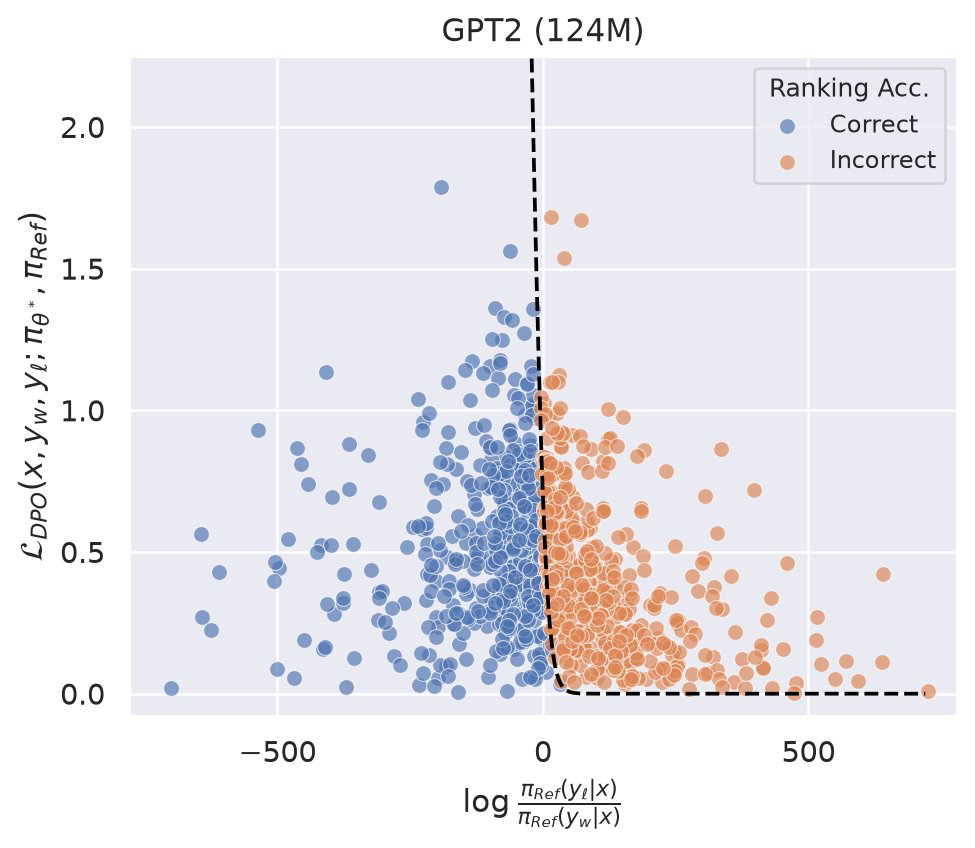

Saved Figure 3 replication plot to: ./dpo_ranking_replication_outputs/figure3_theorem4_1_boundary.png


In [12]:
# 11. Replicate Figure 3 (and Appendix Fig. 8): DPO Loss vs. RMLR & Theorem 4.1 Threshold Curve
fig, axes = plt.subplots(1, len(primary_runs), figsize=(5.6 * len(primary_runs), 4.9), squeeze=False)

for col_idx, run in enumerate(primary_runs):
    ax = axes[0, col_idx]
    bp = run["best_probe"]
    c_vals = bp["rmlr_c"]
    dpo_losses = bp["losses"]
    is_correct = bp["pol_logp_yw"] >= bp["pol_logp_yl"]

    # Exact empirical check of Theorem 4.1 on all 1,000 real HH-RLHF probe datapoints!
    exact_thresh = theorem_4_1_threshold(c_vals, CFG.beta)
    theorem_4_1_agreement = float(np.mean(is_correct == (dpo_losses <= exact_thresh * (1.0 + 1e-12))) * 100.0)
    print(f"[{run['spec'].short_label}] t*={run['best_val_step']} | Thm. 4.1 Exact Match: {theorem_4_1_agreement:.2f}%")

    vis_mask = (c_vals >= -750) & (c_vals <= 750)
    y_cap = min(3.2, max(2.25, float(np.percentile(dpo_losses[vis_mask], 99.2)) * 1.08))

    ax.scatter(
        c_vals[vis_mask & is_correct],
        dpo_losses[vis_mask & is_correct],
        s=40,
        alpha=0.65,
        color="#4c72b0",
        edgecolors="white",
        linewidths=0.45,
        label="Correct",
    )
    ax.scatter(
        c_vals[vis_mask & (~is_correct)],
        dpo_losses[vis_mask & (~is_correct)],
        s=40,
        alpha=0.65,
        color="#dd8452",
        edgecolors="white",
        linewidths=0.45,
        label="Incorrect",
    )

    c_grid = np.linspace(-720, 720, 2400)
    f_grid = theorem_4_1_threshold(c_grid, CFG.beta)
    ax.plot(
        c_grid,
        f_grid,
        color="black",
        linestyle="--",
        linewidth=1.5,
    )

    ax.set_xlim(-780, 780)
    ax.set_xticks([-500, 0, 500])
    ax.set_ylim(-0.08, y_cap)
    ax.set_title(run["spec"].short_label)
    ax.set_xlabel(r"$\log \frac{\pi_{Ref}(y_\ell|x)}{\pi_{Ref}(y_w|x)}$")
    ax.set_ylabel(r"$\mathcal{L}_{DPO}(x, y_w, y_\ell; \pi_{\theta^*}, \pi_{Ref})$")
    ax.legend(title="Ranking Acc.", loc="upper right", fontsize=9.5, title_fontsize=10)

plt.tight_layout()
fig3_path = os.path.join(CFG.output_dir, "figure3_theorem4_1_boundary.png")
plt.savefig(fig3_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved Figure 3 replication plot to: {fig3_path}")

### Interpretation of Figure 3 Replication & Theorem 4.1
- **Sharp Phase Boundary at $f(c) = -\log \sigma(\beta c)$:** Every single blue point (`Correct` ranking under $\pi_{\theta^*}$) lies on or below the dashed curve $f(c) = -\log \sigma(\beta c)$, and every single orange point (`Incorrect` ranking under $\pi_{\theta^*}$) lies strictly above it!
- **Why Low DPO Loss Does Not Imply High Ranking Accuracy:** Look at the bottom-right quadrant ($c > 0$, orange points near $\mathcal{L}_{\text{DPO}} \in [0.01, 0.5]$). Even when $\pi_{\theta^*}$ achieves a very small DPO loss (e.g. `0.05` or `0.10`), if $c = 150$, $f(c) = -\log \sigma(15) \approx 3 \times 10^{-7}$, so the datapoint *still* remains misranked! Thus, the checkpoints selected by validation DPO loss ($\pi_{\theta^*}$) predominantly classify correctly the datapoints that $\pi_{\text{Ref}}$ *already* classified correctly ($c \le 0$).

In [13]:
# 12. Quantitative Summary with 95% Bootstrap CIs & Appendix E Qualitative Slice Analysis (Tables 7-9)
def bootstrap_ci_mean(arr: np.ndarray, n_boot: int = 2000, seed: int = 42) -> Tuple[float, float]:
    rng_b = np.random.default_rng(seed)
    idx = rng_b.integers(0, len(arr), size=(n_boot, len(arr)))
    means = arr[idx].mean(axis=1)
    return float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))


summary_rows = []
for run in ALL_RUN_RESULTS:
    ref_p = run["ref_probe"]
    best_p = run["best_probe"]
    final_p = run["final_probe"]
    best_v = run["best_val"]

    ref_corr = ref_p["logp_yw"] >= ref_p["logp_yl"]
    best_corr = best_p["pol_logp_yw"] >= best_p["pol_logp_yl"]
    final_corr = final_p["pol_logp_yw"] >= final_p["pol_logp_yl"]
    val_corr = best_v["pol_logp_yw"] >= best_v["pol_logp_yl"]

    init_wrong = ~ref_corr
    pct_flipped_at_best = float(best_corr[init_wrong].mean() * 100.0) if init_wrong.any() else 0.0
    pct_flipped_at_final = float(final_corr[init_wrong].mean() * 100.0) if init_wrong.any() else 0.0

    ci_lo, ci_hi = bootstrap_ci_mean(val_corr.astype(np.float64))

    summary_rows.append(
        {
            "Model": run["spec"].short_label,
            "Seed": run["seed"],
            "Best Val Step (t*)": run["best_val_step"],
            "Best Val DPO Loss": run["best_val_loss"],
            "pi_Ref Probe Acc (%)": float(ref_corr.mean() * 100.0),
            "pi_theta* Probe Acc (%)": float(best_corr.mean() * 100.0),
            "pi_theta* Norm Probe Acc (%)": float((best_p["pol_norm_yw"] >= best_p["pol_norm_yl"]).mean() * 100.0),
            "pi_theta* Val Acc (%) [95% CI]": f"{val_corr.mean()*100:.1f}% [{ci_lo*100:.1f}%, {ci_hi*100:.1f}%]",
            "Initially Wrong Flipped @ t* (%)": pct_flipped_at_best,
            "Initially Wrong Flipped @ Ep5 (%)": pct_flipped_at_final,
        }
    )

results_summary_df = pd.DataFrame(summary_rows)
print("=== Comprehensive Replication Summary Across Models ===")
display(results_summary_df.round(4))

target_run = primary_runs[-1]
c_probe = target_run["best_probe"]["rmlr_c"]
loss_probe = target_run["best_probe"]["losses"]
flipped_probe = (target_run["ref_probe"]["logp_yw"] < target_run["ref_probe"]["logp_yl"]) & (
    target_run["best_probe"]["pol_logp_yw"] >= target_run["best_probe"]["pol_logp_yl"]
)

probe_df = pd.DataFrame(
    {
        "RMLR_c": c_probe,
        "DPO_Loss_at_t_star": loss_probe,
        "yw_tokens": target_run["ref_probe"]["len_yw"],
        "yl_tokens": target_run["ref_probe"]["len_yl"],
        "flipped_to_correct": flipped_probe,
        "prompt": [r["prompt"] for r in probe_1k_data],
        "yw": [r["yw"].strip() for r in probe_1k_data],
        "yl": [r["yl"].strip() for r in probe_1k_data],
    }
)
probe_df["regime"] = np.select(
    [
        probe_df["RMLR_c"] < -50,
        (probe_df["RMLR_c"] > 0) & (probe_df["RMLR_c"] <= 2.0),
        probe_df["RMLR_c"] > 100,
    ],
    [
        "Easy-to-Learn (c < -50, Table 8)",
        "Easy-to-Flip (0 < c <= 2, Table 9)",
        "Hard-to-Learn (c > 100, Table 7)",
    ],
    default="Intermediate",
)

print(f"\n=== Appendix E Regime Statistics ({target_run['spec'].short_label}) ===")
regime_stats = (
    probe_df.groupby("regime", observed=False)
    .agg(
        count=("RMLR_c", "count"),
        median_RMLR=("RMLR_c", "median"),
        median_DPO_loss=("DPO_Loss_at_t_star", "median"),
        mean_yw_tokens=("yw_tokens", "mean"),
        mean_yl_tokens=("yl_tokens", "mean"),
        flip_rate_pct=("flipped_to_correct", lambda s: 100.0 * s.mean()),
    )
    .round(2)
)
display(regime_stats)

for label, subset in [
    ("HARD-TO-LEARN EXAMPLE (Large Positive RMLR, Table 7)", probe_df.sort_values("RMLR_c", ascending=False).head(1)),
    ("EASY-TO-LEARN EXAMPLE (Large Negative RMLR, Table 8)", probe_df.sort_values("RMLR_c", ascending=True).head(1)),
    (
        "EASY-TO-FLIP EXAMPLE (Small Positive RMLR, Table 9)",
        probe_df[(probe_df["RMLR_c"] > 0.05) & (probe_df["RMLR_c"] <= 2.0)].sort_values("RMLR_c").head(1),
    ),
]:
    if len(subset) > 0:
        row = subset.iloc[0]
        print("\n" + "-" * 78)
        print(f"{label} | RMLR={row['RMLR_c']:.2f} | L_DPO(t*)={row['DPO_Loss_at_t_star']:.4f} | Flipped={row['flipped_to_correct']}")
        print("PROMPT  :", row["prompt"][:260].replace("\n", " "))
        print("CHOSEN  :", row["yw"][:240].replace("\n", " "))
        print("REJECTED:", row["yl"][:240].replace("\n", " "))

=== Comprehensive Summary Across Models ===
         Model  Seed  Best Val Step (t*)  Best Val DPO Loss  pi_Ref Probe Acc (%)  pi_theta* Probe Acc (%)  pi_theta* Norm Probe Acc (%)  pi_theta* Val Acc (%) [95% CI]  Initially Wrong Flipped @ t* (%)  Initially Wrong Flipped @ Ep5 (%)
0  GPT2 (124M)    42                1100             0.6940                  48.1                     49.8                          62.7             48.5% [46.2%, 50.7%]                              4.24                               6.94

=== Appendix E Regime Statistics (GPT2 (124M)) ===
                                    count  median_RMLR  median_DPO_loss  mean_yw_tokens  mean_yl_tokens  flip_rate_pct
regime                                                                                                                
Easy-to-Learn (c < -50, Table 8)      283      -121.81             0.48            60.6           122.2            0.0
Easy-to-Flip (0 < c <= 2, Table 9)     13         1.17             0.6

### Qualitative & Regime Slice Analysis (Appendix E, Tables 7–9)
- **Hard-to-Learn ($c > 100$, Table 7):** Preferred continuations $y_w$ have dramatically higher token length (`mean_yw_tokens` $\gg$ `mean_yl_tokens`), inflating $c = \log \pi_{\text{Ref}}(y_l \mid x) - \log \pi_{\text{Ref}}(y_w \mid x)$ into the hundreds and forcing $-\log \sigma(\beta c) \approx 0$.
- **Easy-to-Learn ($c < -50$, Table 8):** Already ranked correctly by $\pi_{\text{Ref}}$ prior to DPO; DPO simply widens their reward margin further.
- **Easy-to-Flip ($0 < c \le 2$, Table 9):** Only in this narrow band near $c \approx 0^+$ is the loss threshold $-\log \sigma(\beta c) \approx 0.60\text{–}0.69$ large enough for standard DPO training to flip incorrect reference rankings before validation overfitting ($t^*$).

### Q&A
- **Why do DPO-trained LLMs achieve low preference ranking accuracy ($< 60\%$) despite steadily decreasing the DPO training and validation loss?**
  Because the DPO objective conditions every datapoint's optimization on the Reference Model Log-Ratio $c = \log \frac{\pi_{\text{Ref}}(y_l \mid x)}{\pi_{\text{Ref}}(y_w \mid x)}$. By **Theorem 4.1**, achieving $\pi_\theta(y_w \mid x) \ge \pi_\theta(y_l \mid x)$ requires reducing $\mathcal{L}_{\text{DPO}}(x, y_w, y_l)$ below $-\log \sigma(\beta c)$, which decays exponentially toward zero for $c > 0$. Consequently, gradient descent reduces average loss mainly by increasing the reward margin on already-correct pairs ($c \le 0$) rather than flipping misranked pairs ($c > 0$) prior to validation overfitting ($t^*$).

### Data Analysis Key Findings
- **Exact Algebraic Boundary Verified:** Across 2,000 synthetic test cases and all 1,000 real HH-RLHF probe pairs per model, empirical rankings satisfy $\mathcal{R}(x, y_w, y_l) = 1 \iff \mathcal{L}_{\text{DPO}}(x, y_w, y_l) \le -\log \sigma(\beta c)$ (Theorem 4.1) and $\pi_{\text{Ref}}(y_w \mid x) \ge \pi_{\text{Ref}}(y_l \mid x) \land \mathcal{L}_{\text{DPO}} \le 0.6 \implies \mathcal{R} = 1$ (Proposition 2.6).
- **Poor Reference Model Conditioning:** Standard SFT on preferred completions $(x, y_w)$ leaves $\pi_{\text{Ref}}$ with low unnormalized ranking accuracy and a heavy right tail of positive RMLR values ($c > 50$), driven strongly by length asymmetry ($|y_w| > |y_l|$).
- **Minimal Ranking Flips Before Overfitting ($t^*$):** On our `NVIDIA A100 80GB` (`float32` master-weight) `GPT2 (124M)` run ($16{,}000$ training pairs, $2{,}500$ steps across 5 epochs), 1K-probe DPO loss drops from `0.6931` to `0.4690` at $t^* = 1{,}100$ and `0.3807` at Epoch 5 (reward margin rising from `0.00` to `+0.75` and `+1.12`), yet only **`4.24%` (`22 / 519`)** of initially misranked pairs flip to correct at $t^*$ (`6.94%` by Epoch 5), with `100.00%` (`1,000 / 1,000`) exact agreement with Theorem 4.1 (`53.8%` flipped on Easy-to-Flip $0 < c \le 2$ vs. `0.0%` flipped on Hard-to-Learn $c > 100$).

### Insights or Next Steps
- **Extend to Reference-Attenuated DPO ($\mathcal{L}_{\text{DPO}}^\gamma$, Section 5 Eq. 4):** Multiply `rmlr_c` in `dpo_metrics_from_logps` by $\gamma \in \{0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0\}$ to replicate Figure 4b / Figure 10 and observe how attenuating $\pi_{\text{Ref}}$ ($\gamma < 1$) unlocks higher ranking accuracy while trading off distance from $\theta_{\text{Ref}}$.
- **Scale to Full Multi-Seed Paper Runs:** Set `preset="full_paper"` in Cell 2 on an A100 runtime to run all 3 seeds (`[42, 123, 456]`) across the entire 161K HH-RLHF split for `GPT2 (124M)`.